## FASE 0: Introducción, instalación y lectura inicial del dataframe

Este es el notebook del proyecto 6 que va a realizar un Análisis Exploratorio de Datos (EDA por sus siglas en inglés) a un archivo público de Estados Unidos.

El archivo en concreto es un .csv en el que se recopilan datos sobre el COVID19 de todos los estados federales que pertenecen a EE.UU.. Se recopila diversa información referente a la pandemia, la enfermedad y los pacientes.

Para comenzar con nuestro Análisis, lo primero que vamos a hacer es la carga de los datos como un dataframe (df) además de importar las librerías necesarias para poder trabajar cómodamente en python (y jupyter). 
Las librerías se incluyen en el archivo requirements.txt para la fácil reproducibilidad del notebook.

También configuraremos la estética de los gráficos de manera quequeden homogéneos y puedan ser fácilmente modificados

In [41]:
# Instalamos e importamos las librerías necesarias
%pip install -r requirements.txt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Configuración estética para los gráficos
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (9, 5)
pd.set_option('display.max_columns', 30)
np.random.seed(42)

# Cargamos el dataset
df = pd.read_csv('all-states-history.csv')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Con los datos ya cargados, vamos a estudiar de manera superficial que tipos de datos tenemos. 

Con unos pocos comandos, podemos esbozar una idea de lo que el dataset nos ofrece, tales como el número de columnas, los tipos de datos que tienen esas columnas, el nombre de las columnas, etc.

Esto nos puede ayudar a orientar el análisis de manera más concreta en los siguientes pasos.

In [42]:
# Comprobamos el número de filas y columnas totales
print(f"Forma del dataset: {df.shape}")

# Vemos el tipo de dato y el nombre de cada columna
df.info()

Forma del dataset: (20780, 41)
<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   date                              20780 non-null  str    
 1   state                             20780 non-null  str    
 2   death                             19930 non-null  float64
 3   deathConfirmed                    9422 non-null   float64
 4   deathIncrease                     20780 non-null  int64  
 5   deathProbable                     7593 non-null   float64
 6   hospitalized                      12382 non-null  float64
 7   hospitalizedCumulative            12382 non-null  float64
 8   hospitalizedCurrently             17339 non-null  float64
 9   hospitalizedIncrease              20780 non-null  int64  
 10  inIcuCumulative                   3789 non-null   float64
 11  inIcuCurrently                    11636 non-nul

Con estos comandos comprobamos que tenemos 20780 filas y 41 columnas, de las cuales 2 son str (cadenas de caracteres), 30 son float64 (números reales) y 9 son int64 (números enteros).

Además, podemos visualizar el encabezado de las columnas, destacando los Tests Víricos, los incrementos en tests, hospitalizaciones y UCI, etc. También comprobamos que las columnas que son cadenas de carácteres se refieren a la fecha y al estado al que pertenecen los datos recopilados.

Debemos convertir date a tipo de dato fecha para facilitar su manipulación y uso

In [43]:
# Convertimos date a tipo fecha
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df.info()   # debe aparecer datetime64[ns]

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype         
---  ------                            --------------  -----         
 0   date                              20780 non-null  datetime64[us]
 1   state                             20780 non-null  str           
 2   death                             19930 non-null  float64       
 3   deathConfirmed                    9422 non-null   float64       
 4   deathIncrease                     20780 non-null  int64         
 5   deathProbable                     7593 non-null   float64       
 6   hospitalized                      12382 non-null  float64       
 7   hospitalizedCumulative            12382 non-null  float64       
 8   hospitalizedCurrently             17339 non-null  float64       
 9   hospitalizedIncrease              20780 non-null  int64         
 10  inIcuCumulative                   3789 non-null   float64

Con esta breve introducción y primer vistazo a los datos, nos adentramos ya en el tema estadístico. 

Primero hacemos que panda nos de un pequeño resumen estadístico de todas las columnas.

In [44]:
df.describe(include='all')

,date,state,death,deathConfirmed,deathIncrease,deathProbable,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,inIcuCumulative,inIcuCurrently,negative,negativeIncrease,negativeTestsAntibody,...,positiveTestsPeopleAntigen,positiveTestsViral,recovered,totalTestEncountersViral,totalTestEncountersViralIncrease,totalTestResults,totalTestResultsIncrease,totalTestsAntibody,totalTestsAntigen,totalTestsPeopleAntibody,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
count,20780,20780,19930.000000,9422.000000,20780.000000,7593.000000,12382.000000,12382.000000,17339.000000,20780.000000,3789.000000,11636.000000,1.329000e+04,20780.000000,1458.000000,...,633.000000,8.958000e+03,1.200300e+04,5.231000e+03,20780.000000,2.061400e+04,20780.000000,4.789000e+03,3.421000e+03,2200.000000,999.000000,9.197000e+03,2.078000e+04,1.451600e+04,2.078000e+04
unique,NaN,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,WA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,420,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2020-09-02 18:13:30.779595,NaN,3682.216859,3770.182764,24.790712,417.291321,9262.762478,9262.762478,1190.576965,37.360780,1934.191607,359.621176,8.482246e+05,3589.128874,145580.733196,...,25259.048973,1.985001e+05,9.424223e+04,2.702109e+06,5578.147064,2.186936e+06,17508.388210,1.634028e+05,3.089196e+05,165431.783182,168188.246246,9.650105e+05,2.739554e+03,2.304555e+06,1.296143e+04
min,2020-01-13 00:00:00,NaN,0.000000,0.000000,-201.000000,0.000000,1.000000,1.000000,0.000000,-12257.000000,6.000000,0.000000,0.000000e+00,-968686.000000,587.000000,...,3.000000,0.000000e+00,2.000000e+00,0.000000e+00,-16946.000000,0.000000e+00,-130545.000000,0.000000e+00,1.000000e+00,1.000000,3.000000,0.000000e+00,-1.043744e+06,0.000000e+00,-1.154583e+06
25%,2020-06-02 00:00:00,NaN,161.250000,607.000000,0.000000,79.000000,985.250000,985.250000,166.500000,0.000000,501.000000,60.000000,5.394125e+04,0.000000,11242.000000,...,2682.000000,1.615925e+04,3.379000e+03,1.937935e+05,0.000000,1.040498e+05,1205.750000,1.896500e+04,2.004700e+04,54912.750000,37675.500000,1.414700e+05,0.000000e+00,1.324600e+05,0.000000e+00
50%,2020-09-03 00:00:00,NaN,1108.000000,2409.500000,6.000000,216.000000,4472.000000,4472.000000,531.000000,0.000000,1295.000000,172.000000,3.059720e+05,141.500000,78888.000000,...,17763.000000,6.535900e+04,1.761800e+04,9.053220e+05,0.000000,6.552670e+05,6125.000000,8.465200e+04,1.233840e+05,103967.500000,144130.000000,4.193720e+05,0.000000e+00,7.316510e+05,1.896500e+03
75%,2020-12-05 00:00:00,NaN,4387.500000,5462.000000,24.000000,460.000000,12248.500000,12248.500000,1279.000000,36.000000,2451.000000,380.000000,1.056611e+06,3916.000000,162925.500000,...,47012.000000,2.246800e+05,9.315250e+04,2.780542e+06,0.000000,2.264766e+06,19086.500000,2.300110e+05,4.327270e+05,183103.000000,255251.000000,1.229298e+06,2.478000e+03,2.496925e+06,1.244100e+04
max,2021-03-07 00:00:00,NaN,54124.000000,21177.000000,2559.000000,2594.000000,82237.000000,82237.000000,22851.000000,16373.000000,9263.000000,5225.000000,1.018694e+07,212974.000000,864153.000000,...,81803.000000,2.628176e+06,2.502609e+06,3.969510e+07,324671.000000,4.964601e+07,473076.000000,1.054711e+06,2.664340e+06,995580.000000,580372.000000,1.124825e+07,8.208170e+05,4.964601e+07,2.164543e+06


Con la tabla desplegada podemos detectar las variables categóricas del dataset, que en este caso coinciden con las columnas de los datos tipo str.
De estas variables categóricas podemos decir que hay 420 días únicos y 56 estados únicos. Veamos en profundidad la columna "state" ya que en EE.UU. hay únicamente 50 estados federales 

str
Nulos: 0 (0.0%)
Valores únicos: 56
5682     MO
20695    VA
5276     GU
9903     TX
10393    NH
6060     GU
15091    MP
2078     CO
4788     MS
18811    VT
Name: state, dtype: str
         n     %
state           
WA     420  2.02
MA     411  1.98
VA     406  1.95
FL     404  1.94
NJ     392  1.89
NE     387  1.86
IN     375  1.80
CT     373  1.79
MI     372  1.79
RI     372  1.79
WY     372  1.79
NY     371  1.79
PA     370  1.78
TX     370  1.78
VT     370  1.78
WI     370  1.78
AZ     369  1.78
CA     369  1.78
CO     369  1.78
GA     369  1.78
HI     369  1.78
IL     369  1.78
NC     369  1.78
NH     369  1.78
OR     369  1.78
SC     369  1.78
DC     368  1.77
MD     368  1.77
NM     368  1.77
NV     368  1.77
OH     368  1.77
TN     368  1.77
AK     367  1.77
AR     367  1.77
DE     367  1.77
IA     367  1.77
KS     367  1.77
KY     367  1.77
MN     367  1.77
WV     367  1.77
AL     366  1.76
ID     366  1.76
LA     366  1.76
ME     366  1.76
MO     366  1.76
MS     366  1.76
M

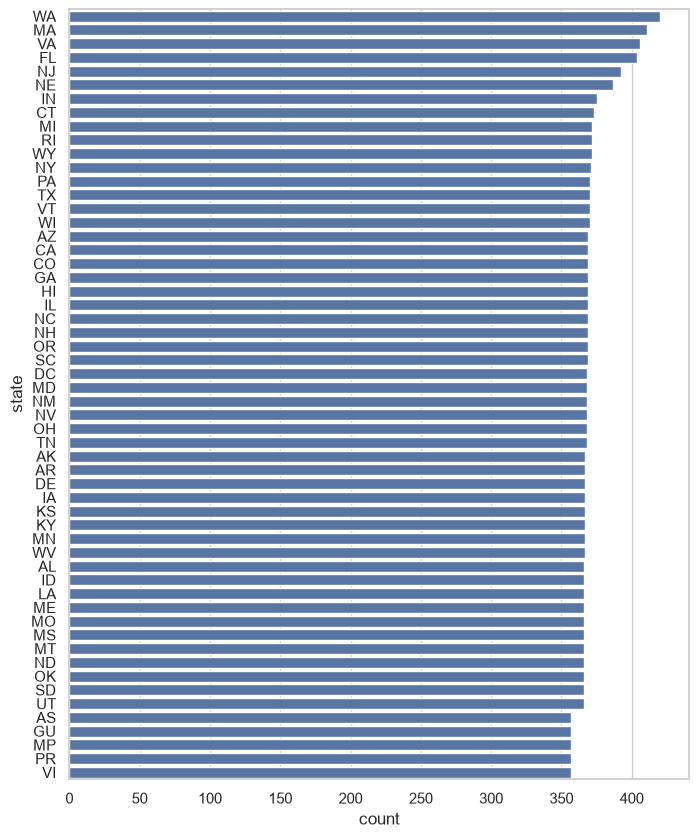

In [45]:
col = df["state"]

print(col.dtype)
print("Nulos:", col.isna().sum(), f"({col.isna().mean():.1%})")
print("Valores únicos:", col.nunique())
print(col.sample(10, random_state=1))

# Frecuencias absolutas y relativas
freq = pd.DataFrame({
    "n": col.value_counts(dropna=False),
    "%": col.value_counts(normalize=True, dropna=False).mul(100).round(2)
})
print(freq)

# Detectar categorías duplicadas por mayúsculas, espacios, etc.
print(col.str.strip().str.lower().nunique(), "vs", col.nunique())

# Gráfico
plt.figure(figsize=(8, 10))
sns.countplot(y=col, order=col.value_counts().index)
plt.show()

Desgranando la columna desciframos que los 6 estados faltantes no son en realidad estados en sí mismos, si no territorios pertenecientes a Estados Unidos, siendo Guam, las Islas Vírgenes, Samoa Estadounidense, la Islas Marianas del Norte, Puerto Rico y Washington D.C.

## Fase 1: Calidad de datos, limpieza e imputación

Con los datos cargados y la columna date ya convertida a fecha, toca comprobar cuánta información tenemos de verdad. En el primer vistazo vimos que muchas columnas tienen pocos valores no nulos, así que antes de analizar nada conviene entender qué falta, por qué falta y qué hacemos con ello.

Seguiremos tres pasos: primero un diagnóstico de los valores nulos, después la identificación del mecanismo de pérdida (por qué faltan) y, por último, una estrategia de limpieza e imputación que cerraremos con una validación. A lo largo de la fase df conserva los datos originales (solo lo ordenamos por estado y fecha) y todos los cambios se hacen sobre una copia llamada df_clean.

### Comprobaciones previas

Casi todos los cálculos de esta fase se hacen serie por serie (cada estado es una serie temporal), así que ordenamos el dataset por estado y fecha y comprobamos que la estructura es la esperada: sin filas duplicadas y sin días saltados dentro de cada serie.

In [46]:
# Ordenamos por estado y fecha: es la base para cualquier cálculo por serie temporal
df = df.sort_values(["state", "date"]).reset_index(drop=True)

# Comprobaciones de integridad: sin filas duplicadas y sin días saltados dentro de la serie de cada estado
duplicados = df.duplicated(["state", "date"]).sum()
rango = df.groupby("state")["date"].agg(["min", "max", "count"])
rango["dias_esperados"] = (rango["max"] - rango["min"]).dt.days + 1
dias_saltados = (rango["dias_esperados"] - rango["count"]).sum()

print(f"Filas duplicadas (state, date): {duplicados}")
print(f"Días saltados dentro de la serie de cada estado: {dias_saltados}")
print(f"Rango temporal global: {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"Primer registro de cada estado: entre el {rango['min'].min().date()} y el {rango['min'].max().date()}")

Filas duplicadas (state, date): 0
Días saltados dentro de la serie de cada estado: 0
Rango temporal global: 2020-01-13 -> 2021-03-07
Primer registro de cada estado: entre el 2020-01-13 y el 2020-03-16


Todo en orden: no hay filas duplicadas ni días saltados, así que cada estado tiene una serie diaria continua (esto nos permitirá interpolar en el tiempo con seguridad más adelante). Lo que sí varía es cuándo empieza cada serie: los primeros registros van del 13 de enero al 16 de marzo de 2020 y todas terminan el 7 de marzo de 2021, de modo que hay estados con 420 días de datos (WA) y otros con 357 (AS, GU, MP, PR y VI).

### Diagnóstico de valores nulos

Empezamos midiendo cuántos nulos tiene cada columna y las clasificamos por gravedad: leve (menos del 5%), moderada (5-30%), alta (30-60%), muy alta (60-90%) y crítica (más del 90%).

In [47]:
# Resumen de nulos por columna: cantidad, porcentaje y tipo de dato
nulos = pd.DataFrame({
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values("pct_nulos", ascending=False)

# Clasificamos cada columna según la gravedad de sus faltantes
tramos = [-1, 0, 5, 30, 60, 90, 100]
etiquetas = ["Completa (0%)", "Leve (0-5%)", "Moderada (5-30%)", "Alta (30-60%)", "Muy alta (60-90%)", "Crítica (>90%)"]
nulos["gravedad"] = pd.cut(nulos["pct_nulos"], bins=tramos, labels=etiquetas)

total_nulos = df.isna().sum().sum()
print(f"Columnas con algún nulo: {(nulos['n_nulos'] > 0).sum()} de {df.shape[1]}")
print(f"Celdas nulas: {total_nulos:,} de {df.size:,} ({total_nulos / df.size:.1%})")
print()
print(nulos["gravedad"].value_counts().sort_index())

nulos[nulos["n_nulos"] > 0]

Columnas con algún nulo: 30 de 41
Celdas nulas: 373,695 de 851,980 (43.9%)

gravedad
Completa (0%)        11
Leve (0-5%)           3
Moderada (5-30%)      1
Alta (30-60%)        11
Muy alta (60-90%)     9
Crítica (>90%)        6
Name: count, dtype: int64


,n_nulos,pct_nulos,dtype,gravedad
positiveTestsPeopleAntigen,20147,96.95,float64,Crítica (>90%)
negativeTestsPeopleAntibody,19808,95.32,float64,Crítica (>90%)
totalTestsPeopleAntigen,19781,95.19,float64,Crítica (>90%)
positiveTestsPeopleAntibody,19686,94.74,float64,Crítica (>90%)
onVentilatorCumulative,19490,93.79,float64,Crítica (>90%)
negativeTestsAntibody,19322,92.98,float64,Crítica (>90%)
totalTestsPeopleAntibody,18580,89.41,float64,Muy alta (60-90%)
positiveTestsAntigen,18547,89.25,float64,Muy alta (60-90%)
positiveTestsAntibody,17434,83.90,float64,Muy alta (60-90%)
totalTestsAntigen,17359,83.54,float64,Muy alta (60-90%)


De las 41 columnas, 30 tienen algún nulo y en conjunto faltan 373.695 de las 851.980 celdas del dataset (un 43,9%). Hay 6 columnas críticas con más de un 90% de nulos, entre ellas positiveTestsPeopleAntigen (96,95%) y onVentilatorCumulative (93,79%), y otras 9 en el tramo de 60 a 90%. En el extremo contrario, solo death (4,09%), positive (0,90%) y totalTestResults (0,80%) están casi completas.

Conviene mirar con cuidado las 11 columnas que aparecen como completas: además de date y state, son positiveScore y los 8 incrementos diarios (los que terminan en Increase). Que no tengan nulos no significa que estén bien: más adelante veremos que en los incrementos los datos que faltan están disfrazados de ceros, y que positiveScore vale 0 en todas las filas.

Veamos la misma información en un gráfico de barras, en una matriz de nulos (cada bloque horizontal es un estado, porque el dataset está ordenado por estado y fecha) y en un mapa de calor por estado.

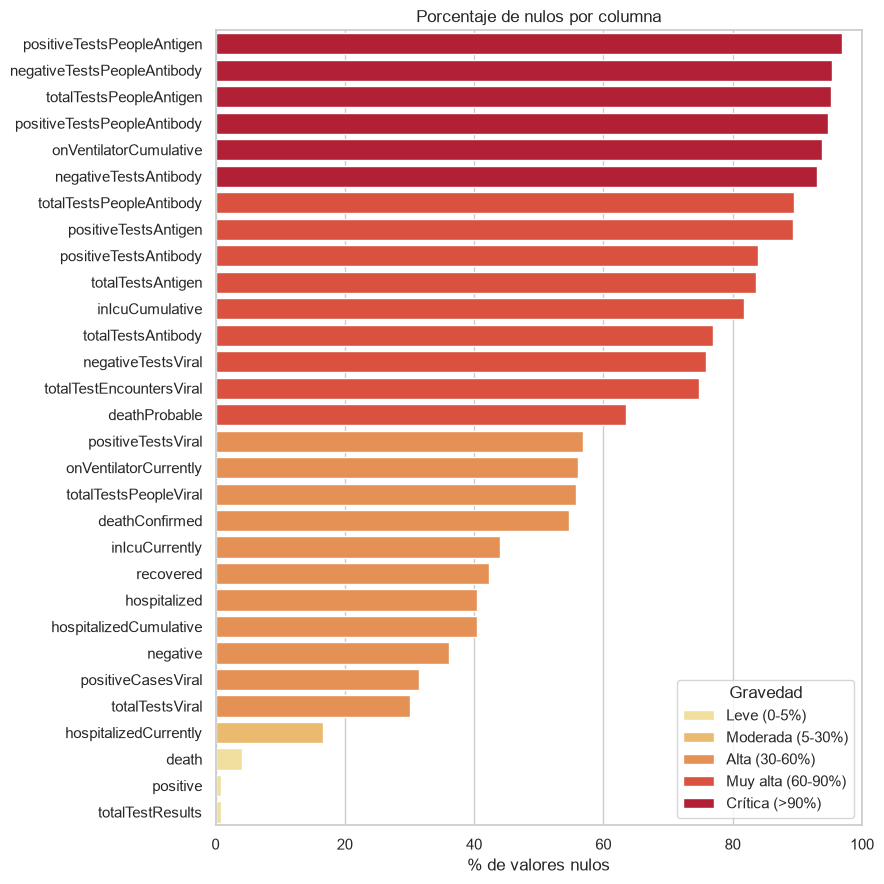

In [48]:
datos = nulos[nulos["n_nulos"] > 0].reset_index(names="columna")
datos["gravedad"] = datos["gravedad"].cat.remove_unused_categories()
paleta = dict(zip(etiquetas[1:], sns.color_palette("YlOrRd", 5)))

plt.figure(figsize=(9, 9))
sns.barplot(data=datos, y="columna", x="pct_nulos", hue="gravedad", palette=paleta, dodge=False)
plt.xlim(0, 100)
plt.xlabel("% de valores nulos")
plt.ylabel("")
plt.title("Porcentaje de nulos por columna")
plt.legend(title="Gravedad", loc="lower right")
plt.tight_layout()
plt.show()

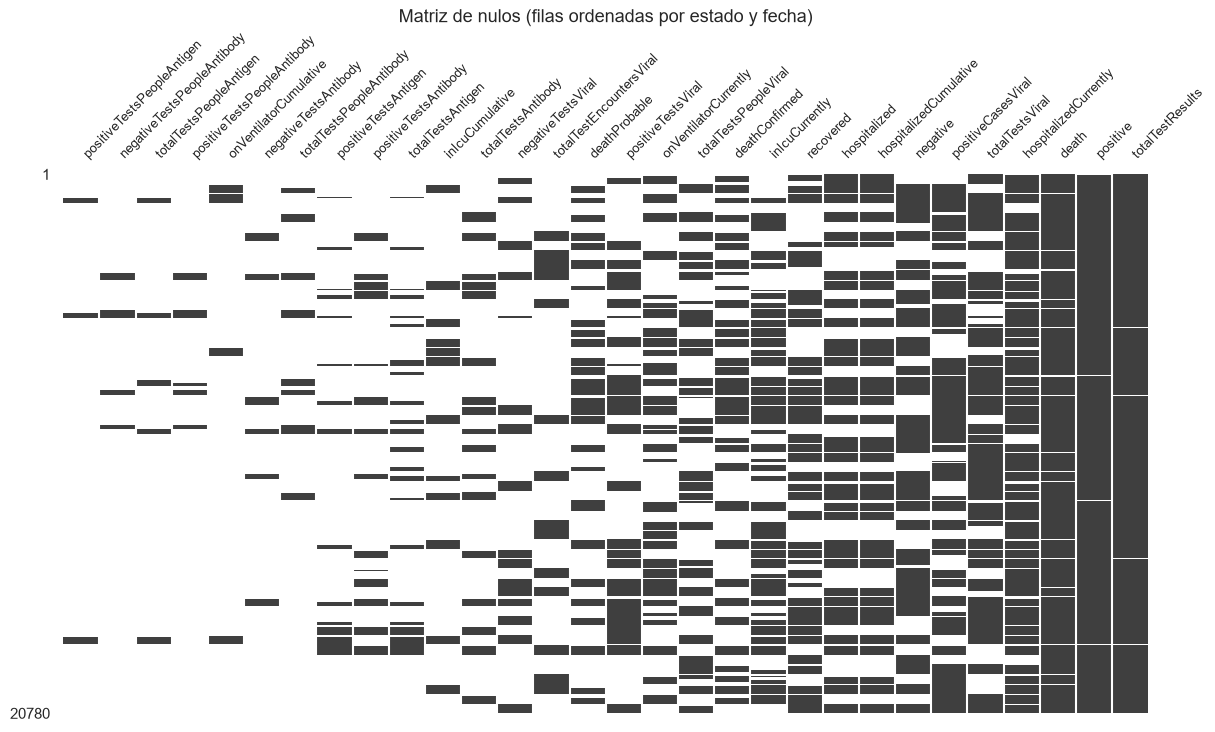

In [49]:
import missingno as msno

cols_con_nulos = nulos.index[nulos["n_nulos"] > 0].tolist()

# El dataset está ordenado por estado y fecha, así que cada bloque horizontal es un estado
msno.matrix(df[cols_con_nulos], figsize=(14, 7), sparkline=False, fontsize=9)
plt.title("Matriz de nulos (filas ordenadas por estado y fecha)", fontsize=13)
plt.show()

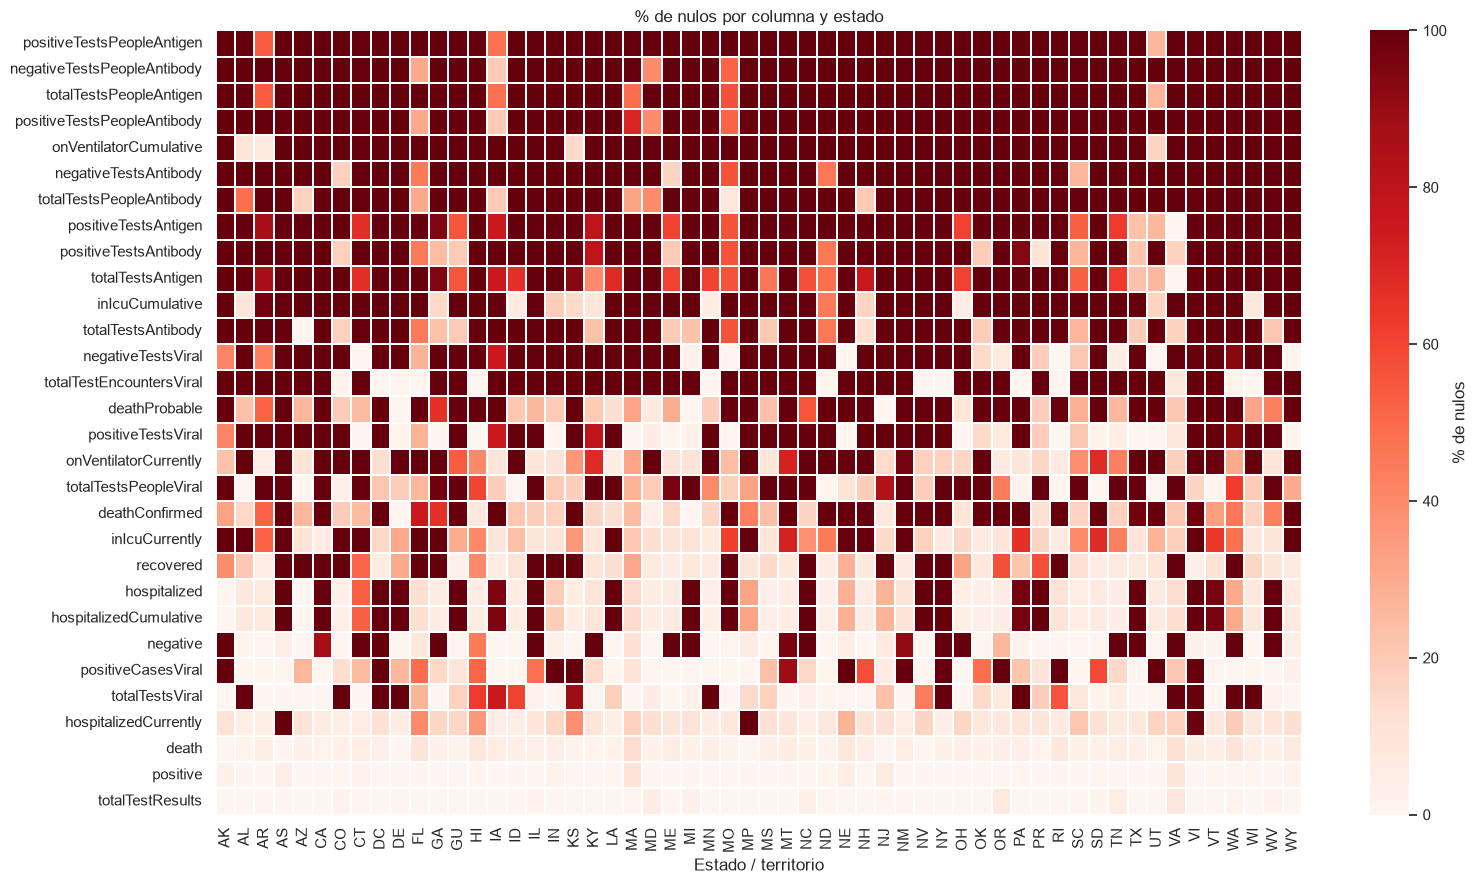

In [50]:
# % de nulos de cada columna dentro de cada estado
nulos_estado = df[cols_con_nulos].isna().groupby(df["state"]).mean().mul(100)

plt.figure(figsize=(16, 9))
sns.heatmap(nulos_estado.T, cmap="Reds", vmin=0, vmax=100, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "% de nulos"})
plt.xlabel("Estado / territorio")
plt.ylabel("")
plt.title("% de nulos por columna y estado")
plt.tight_layout()
plt.show()

Los tres gráficos cuentan la misma historia: los nulos no están repartidos al azar. En la matriz se ven bloques enteros en blanco y en el mapa de calor la mayoría de las columnas son casi del todo oscuras en unos estados y casi del todo claras en otros, es decir, cada estado decide qué métricas publica. También se aprecia que hospitalized y hospitalizedCumulative tienen exactamente el mismo patrón, algo que confirmaremos más adelante. Las tres columnas casi completas (death, positive y totalTestResults) son la excepción: tienen pocos nulos y aparecen con una intensidad parecida en todos los estados.

### Mecanismo de pérdida

Para decidir cómo tratar un nulo hay que saber por qué falta. Se distinguen tres mecanismos: MCAR (falta completamente al azar, sin relación con nada), MAR (la probabilidad de que falte depende de otras variables que sí observamos, como el estado o la fecha) y MNAR (falta por una razón relacionada con el propio valor o con algo que no observamos).

En este dataset cada fila es un estado en un día concreto y la falta de datos tiene una estructura que podemos medir. Para cada columna repartimos sus nulos según dónde caen dentro de la serie de cada estado:

- estado_nunca_reporta: el estado no tiene ningún valor en esa columna en todo el periodo.
- inicio_tardio: nulos anteriores al primer valor que el estado reportó.
- huecos_internos: nulos entre dos valores reportados.
- final_sin_reporte: nulos posteriores al último valor reportado.

Después etiquetamos cada columna con su causa dominante (aquella que explica al menos el 50% de sus nulos).

In [51]:
def anatomia_nulos(datos, columnas):
    """Reparte los nulos de cada columna según su posición dentro de la serie de cada estado:
    - estado_nunca_reporta: el estado no tiene ningún valor en toda la columna
    - inicio_tardio: nulos anteriores al primer valor reportado por el estado
    - huecos_internos: nulos entre dos valores reportados
    - final_sin_reporte: nulos posteriores al último valor reportado
    """
    orden = datos.groupby("state").cumcount()
    filas = {}
    for col in columnas:
        es_nulo = datos[col].isna()
        pos_valida = orden.where(~es_nulo)
        primero = pos_valida.groupby(datos["state"]).transform("min")
        ultimo = pos_valida.groupby(datos["state"]).transform("max")
        filas[col] = {
            "estado_nunca_reporta": (es_nulo & primero.isna()).sum(),
            "inicio_tardio": (es_nulo & (orden < primero)).sum(),
            "huecos_internos": (es_nulo & (orden > primero) & (orden < ultimo)).sum(),
            "final_sin_reporte": (es_nulo & (orden > ultimo)).sum(),
        }
    return pd.DataFrame(filas).T


anatomia = anatomia_nulos(df, cols_con_nulos)

# El reparto tiene que cuadrar con el total de nulos de cada columna
assert (anatomia.sum(axis=1) == nulos.loc[cols_con_nulos, "n_nulos"]).all()

# Peso de cada causa dentro de los nulos de la columna
reparto = anatomia.div(anatomia.sum(axis=1), axis=0)

etiqueta_mecanismo = {
    "estado_nunca_reporta": "Estructural por estado (MNAR probable)",
    "inicio_tardio": "Inicio tardío del reporte (MAR, depende de la fecha)",
    "huecos_internos": "Interrupciones puntuales (MAR/MCAR, imputable)",
    "final_sin_reporte": "Reporte abandonado (MAR, depende de la fecha)",
}

def clasificar(fila):
    if fila.max() < 0.5:
        return "Mixto (varias causas)"
    return etiqueta_mecanismo[fila.idxmax()]

anatomia["mecanismo_probable"] = reparto.apply(clasificar, axis=1)
anatomia.insert(0, "pct_nulos", nulos.loc[cols_con_nulos, "pct_nulos"])
anatomia

,pct_nulos,estado_nunca_reporta,inicio_tardio,huecos_internos,final_sin_reporte,mecanismo_probable
positiveTestsPeopleAntigen,96.95,19680,467,0,0,Estructural por estado (MNAR probable)
negativeTestsPeopleAntibody,95.32,19275,373,0,160,Estructural por estado (MNAR probable)
totalTestsPeopleAntigen,95.19,18903,878,0,0,Estructural por estado (MNAR probable)
positiveTestsPeopleAntibody,94.74,18864,662,0,160,Estructural por estado (MNAR probable)
onVentilatorCumulative,93.79,19314,176,0,0,Estructural por estado (MNAR probable)
negativeTestsAntibody,92.98,18540,699,0,83,Estructural por estado (MNAR probable)
totalTestsPeopleAntibody,89.41,17760,820,0,0,Estructural por estado (MNAR probable)
positiveTestsAntigen,89.25,15601,2775,0,171,Estructural por estado (MNAR probable)
positiveTestsAntibody,83.90,15209,1585,0,640,Estructural por estado (MNAR probable)
totalTestsAntigen,83.54,12665,4523,0,171,Estructural por estado (MNAR probable)


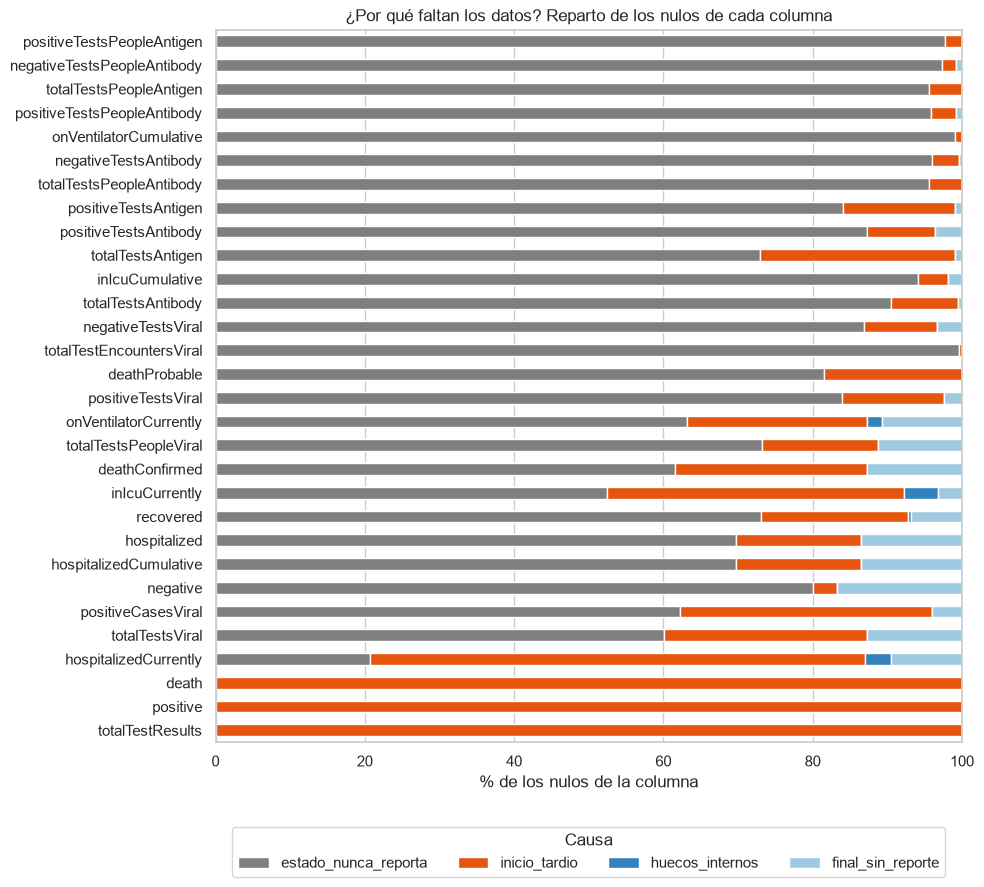

In [52]:
ax = reparto.mul(100).plot(kind="barh", stacked=True, figsize=(10, 9),
                           color=["#7f7f7f", "#e6550d", "#3182bd", "#9ecae1"])
ax.invert_yaxis()
ax.set_xlabel("% de los nulos de la columna")
ax.set_title("¿Por qué faltan los datos? Reparto de los nulos de cada columna")
ax.legend(title="Causa", loc="lower center", bbox_to_anchor=(0.5, -0.2), ncol=4)
plt.tight_layout()
plt.show()

El resultado es muy claro: en 26 de las 30 columnas la causa dominante es que el estado nunca reporta esa métrica, y solo en 4 (death, positive, totalTestResults y hospitalizedCurrently) pesa más que la serie empezara más tarde de lo que marca el calendario. Los nulos de death, positive y totalTestResults son al 100% de inicio tardío, es decir, filas de los primeros días de cada estado en las que todavía no había reporte.

Los huecos internos, los únicos nulos que se parecen a un fallo puntual de reporte, son muy pocos: 776 celdas en total, repartidas entre hospitalizedCurrently (117), inIcuCurrently (409), onVentilatorCurrently (222) y recovered (28). En el resto de columnas no hay ni un hueco entre dos valores reales.

Falta medir cómo de fuerte es la relación entre los nulos y el estado o el mes. Para ello usamos la V de Cramér, que mide la asociación entre dos variables categóricas de 0 (ninguna) a 1 (total), aplicada al indicador «el dato falta» frente al estado y frente al mes. Con 20.780 filas cualquier contraste de hipótesis saldría significativo, así que nos fijamos en el tamaño del efecto y no en el p-valor.

In [53]:
def cramer_v(indicador, grupo):
    """Fuerza de la asociación (0 a 1) entre 'el dato falta' y un grupo (estado, mes...)"""
    tabla = pd.crosstab(grupo, indicador)
    chi2, _, _, _ = stats.chi2_contingency(tabla)
    return np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))


mes = df["date"].dt.to_period("M")
asociacion = pd.DataFrame({
    "pct_nulos": nulos.loc[cols_con_nulos, "pct_nulos"],
    "V_estado": {c: cramer_v(df[c].isna(), df["state"]) for c in cols_con_nulos},
    "V_mes": {c: cramer_v(df[c].isna(), mes) for c in cols_con_nulos},
}).round(2)

asociacion.sort_values("V_estado", ascending=False)

,pct_nulos,V_estado,V_mes
totalTestEncountersViral,74.83,0.99,0.03
negative,36.04,0.95,0.14
positiveTestsViral,56.89,0.94,0.10
onVentilatorCumulative,93.79,0.93,0.09
negativeTestsViral,75.82,0.92,0.12
inIcuCumulative,81.77,0.91,0.16
hospitalized,40.41,0.87,0.28
hospitalizedCumulative,40.41,0.87,0.28
totalTestsViral,30.14,0.87,0.17
totalTestsPeopleViral,55.74,0.85,0.22


La asociación con el estado es muy fuerte: V de Cramér de 0,5 o más en 27 de las 30 columnas, y por encima de 0,9 en seis de ellas (totalTestEncountersViral, negative, positiveTestsViral, onVentilatorCumulative, negativeTestsViral e inIcuCumulative). La asociación con el mes es mucho más débil, salvo en las columnas donde predomina el inicio tardío: death (0,72), hospitalizedCurrently (0,65) y positive (0,61). Con esto descartamos que los datos falten completamente al azar (MCAR).

Veamos también cómo evolucionó el reporte de algunas variables clave a lo largo del tiempo.

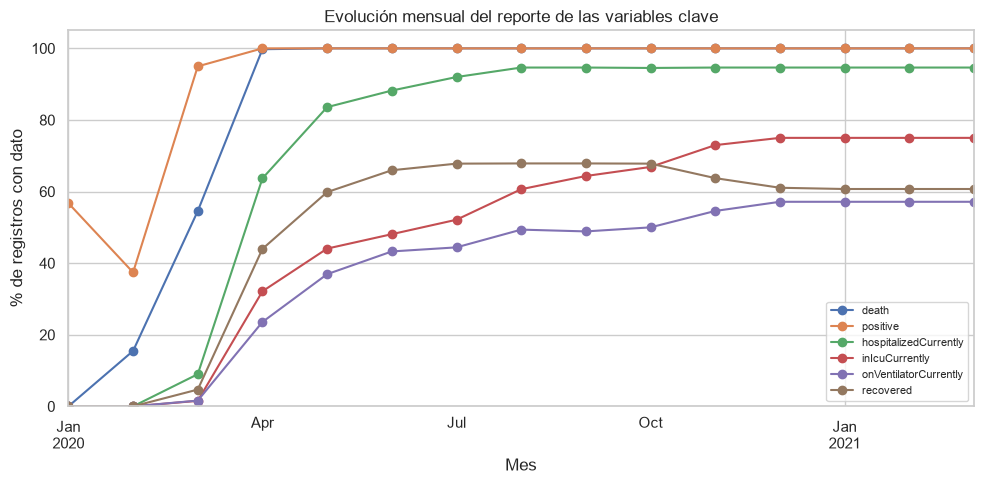

In [54]:
clave = ["death", "positive", "hospitalizedCurrently", "inIcuCurrently", "onVentilatorCurrently", "recovered"]

# % de registros de cada mes que sí traen dato
con_dato = df[clave].notna().groupby(df["date"].dt.to_period("M")).mean().mul(100)
con_dato.index = con_dato.index.to_timestamp()

con_dato.plot(figsize=(10, 5), marker="o")
plt.ylim(0, 105)
plt.xlabel("Mes")
plt.ylabel("% de registros con dato")
plt.title("Evolución mensual del reporte de las variables clave")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

El reporte de death y positive pasa del 0% al 100% en unas pocas semanas de marzo y abril de 2020, a medida que cada estado empieza a publicar, y después se mantiene en el 100%. Las variables de hospitalización se estabilizan en niveles bastante más bajos: hospitalizedCurrently ronda el 95% de los registros, inIcuCurrently el 75% y onVentilatorCurrently el 57%. La curva de recovered sube hasta cerca del 68% y baja hasta en torno al 61% a partir del otoño de 2020, porque algunos estados dejaron de publicarla (es lo que recoge la causa final_sin_reporte).

**Conclusión del diagnóstico.** Los datos no faltan al azar. Se explican por dos variables que sí observamos, el estado y la fecha (formalmente, MAR), pero detrás hay una decisión de cada estado sobre qué estándar de reporte seguir y qué métricas publicar que no está en el dataset. Por prudencia tratamos el caso dominante, los estados que nunca reportan una métrica, como MNAR probable: no se puede estimar con fiabilidad qué valor habrían tenido, así que no vamos a inventarlo. Solo imputaremos allí donde el valor se puede deducir: los huecos cortos entre dos datos reales y los ceros anteriores al primer caso de cada estado.

### Estrategia de limpieza e imputación

Con lo visto, la estrategia queda así:

- Columnas con más de un 90% de nulos: no se imputan. Se apartan en un DataFrame aparte (df_dispersas) para no perder la información, pero salen de df_clean.
- Columnas redundantes o sin información: se eliminan de df_clean.
- Huecos internos de hasta 14 días en acumulados y variables de ocupación: interpolación temporal dentro de cada estado, solo entre dos valores reales.
- Nulos iniciales de los acumulados anteriores al primer caso oficial del estado: se sustituyen por 0.
- Todo lo demás se queda como nulo: no se extrapola ni se rellena con medias.
- Incrementos diarios (los que terminan en Increase): se recalculan a partir del acumulado limpio y los valores negativos se convierten en nulos marcándolos.

Empezamos con las dos primeras reglas.

In [55]:
df_clean = df.copy()

# 1) Columnas críticas (>90% de nulos): no se imputan, se apartan en su propio DataFrame
UMBRAL_CRITICO = 90
cols_criticas = nulos.index[nulos["pct_nulos"] > UMBRAL_CRITICO].tolist()
df_dispersas = df[["state", "date"] + cols_criticas].copy()
df_clean = df_clean.drop(columns=cols_criticas)
print("Columnas apartadas:", cols_criticas)

# 2) Columnas redundantes o sin información
print("\nhospitalized idéntica a hospitalizedCumulative:", df["hospitalized"].equals(df["hospitalizedCumulative"]))
print("Valores distintos en positiveScore:", df["positiveScore"].unique())
df_clean = df_clean.drop(columns=["hospitalized", "positiveScore"])

print(f"\ndf_clean: {df_clean.shape[1]} columnas (de {df.shape[1]} originales)")

Columnas apartadas: ['positiveTestsPeopleAntigen', 'negativeTestsPeopleAntibody', 'totalTestsPeopleAntigen', 'positiveTestsPeopleAntibody', 'onVentilatorCumulative', 'negativeTestsAntibody']

hospitalized idéntica a hospitalizedCumulative: True
Valores distintos en positiveScore: [0]

df_clean: 33 columnas (de 41 originales)


Se apartan 6 columnas (positiveTestsPeopleAntigen, negativeTestsPeopleAntibody, totalTestsPeopleAntigen, positiveTestsPeopleAntibody, onVentilatorCumulative y negativeTestsAntibody): en todas ellas más del 90% de las filas están vacías y 50 o más de los 56 estados no las reportan nunca, así que cualquier imputación sería casi inventar la columna entera. Además descartamos hospitalized, que es idéntica a hospitalizedCumulative, y positiveScore, que vale 0 en todas las filas.

Antes de imputar clasificamos las columnas que quedan en tres grupos, porque cada tipo de variable se trata de forma distinta: acumulados (cuentas que solo deberían crecer), variables instantáneas (la «foto» diaria de ocupación hospitalaria) e incrementos diarios (la diferencia de un acumulado entre dos días consecutivos).

In [56]:
# Cada acumulado y el incremento diario que se deriva de él
pares_incremento = {
    "positive": "positiveIncrease",
    "death": "deathIncrease",
    "hospitalizedCumulative": "hospitalizedIncrease",
    "negative": "negativeIncrease",
    "totalTestResults": "totalTestResultsIncrease",
    "totalTestsViral": "totalTestsViralIncrease",
    "totalTestsPeopleViral": "totalTestsPeopleViralIncrease",
    "totalTestEncountersViral": "totalTestEncountersViralIncrease",
}
cols_incremento = list(pares_incremento.values())

# Variables "foto del día" (ocupación actual): no son acumulados
instantaneas = ["hospitalizedCurrently", "inIcuCurrently", "onVentilatorCurrently"]

# El resto de columnas numéricas son acumulados
acumulados = [c for c in df_clean.select_dtypes("number").columns
              if c not in cols_incremento and c not in instantaneas]

print("Acumulados:", len(acumulados), "| Instantáneas:", len(instantaneas), "| Incrementos:", len(cols_incremento))
print(acumulados)

Acumulados: 20 | Instantáneas: 3 | Incrementos: 8
['death', 'deathConfirmed', 'deathProbable', 'hospitalizedCumulative', 'inIcuCumulative', 'negative', 'negativeTestsViral', 'positive', 'positiveCasesViral', 'positiveTestsAntibody', 'positiveTestsAntigen', 'positiveTestsViral', 'recovered', 'totalTestEncountersViral', 'totalTestResults', 'totalTestsAntibody', 'totalTestsAntigen', 'totalTestsPeopleAntibody', 'totalTestsPeopleViral', 'totalTestsViral']


Antes de tocar los incrementos diarios hay que entenderlos. Comparamos cada uno con su acumulado: cuántos días negativos tiene, qué valor toma cuando el acumulado es nulo y si coincide con la diferencia entre días consecutivos del acumulado.

In [57]:
resumen = []
for acum, inc in pares_incremento.items():
    dif = df.groupby("state")[acum].diff()
    valido = dif.notna()
    resumen.append({
        "incremento": inc,
        "acumulado": acum,
        "n_negativos": int((df[inc] < 0).sum()),
        "minimo": df[inc].min(),
        "% de 0s cuando el acumulado es nulo": round((df.loc[df[acum].isna(), inc] == 0).mean() * 100, 1),
        "% que coincide con diff() del acumulado": round((dif[valido] == df.loc[valido, inc]).mean() * 100, 1),
    })
display(pd.DataFrame(resumen).set_index("incremento"))

for c in ["positiveIncrease", "deathIncrease"]:
    neg = df.loc[df[c] < 0, c]
    pos_total = df.loc[df[c] > 0, c].sum()
    print(f"\n{c}: {len(neg)} días negativos; los negativos suman {neg.sum():,.0f} frente a {pos_total:,.0f} de incrementos positivos ({abs(neg.sum()) / pos_total:.3%})")
    print("  estados con más días negativos:", df.loc[df[c] < 0, "state"].value_counts().head(5).to_dict())

,acumulado,n_negativos,minimo,% de 0s cuando el acumulado es nulo,% que coincide con diff() del acumulado
incremento,,,,,
positiveIncrease,positive,24,-7757,100.0,100.0
deathIncrease,death,73,-201,100.0,100.0
hospitalizedIncrease,hospitalizedCumulative,88,-12257,100.0,100.0
negativeIncrease,negative,70,-968686,99.9,100.0
totalTestResultsIncrease,totalTestResults,49,-130545,100.0,100.0
totalTestsViralIncrease,totalTestsViral,37,-1154583,99.9,100.0
totalTestsPeopleViralIncrease,totalTestsPeopleViral,37,-1043744,99.9,100.0
totalTestEncountersViralIncrease,totalTestEncountersViral,7,-16946,100.0,100.0



positiveIncrease: 24 días negativos; los negativos suman -9,584 frente a 28,765,977 de incrementos positivos (0.033%)
  estados con más días negativos: {'PR': 4, 'DE': 3, 'VI': 3, 'CT': 2, 'HI': 2}

deathIncrease: 73 días negativos; los negativos suman -1,043 frente a 516,194 de incrementos positivos (0.202%)
  estados con más días negativos: {'WA': 11, 'NE': 9, 'AZ': 6, 'AR': 4, 'CO': 4}


Tres hallazgos importantes. Primero, los incrementos son exactamente la diferencia diaria de su acumulado (100% de coincidencia donde ambos existen), así que un incremento negativo significa que el acumulado bajó ese día: una corrección administrativa del estado, no un dato real. Segundo, cuando el acumulado es nulo el incremento no es nulo sino 0 (entre el 99,9% y el 100% de las veces): los nulos están disfrazados de ceros, lo que explica que la mediana de muchos incrementos sea 0. Y tercero, los negativos son pocos y pequeños frente al total: en positiveIncrease suman -9.584 frente a más de 28,7 millones de positivos nuevos (un 0,03%) y en deathIncrease -1.043 frente a 516.194 (un 0,2%), concentrados en pocos estados.

Hay un detalle más: varios de los mínimos más extremos (por ejemplo, -968.686 en negativeIncrease) no son correcciones, sino un artefacto. En hasta 6 filas por columna el acumulado pasa de tener valor a ser nulo y el incremento recoge un negativo igual al último acumulado conocido.

#### Imputación de acumulados y variables instantáneas

Aplicamos las reglas estado a estado. Primero interpolamos los huecos internos (solo entre dos valores reales, sin extrapolar nunca, y solo si duran 14 días o menos) y después sustituimos por 0 los nulos iniciales de los acumulados que caen antes del primer caso positivo del estado. Lo hacemos en este orden para que los ceros no actúen como punto de anclaje de la interpolación; ambas reglas trabajan sobre zonas distintas de la serie. Si un estado no ha tenido ningún positivo en todo el periodo, no se le aplican ceros.

In [58]:
# --- Paso A: interpolación temporal de los huecos internos, estado a estado ---
MAX_HUECO = 14   # días: los huecos internos más largos que esto se dejan sin rellenar

def interpolar_huecos_cortos(serie, max_hueco):
    """Interpola solo entre dos valores reales (nunca extrapola) y solo si el hueco es corto"""
    interpolada = serie.interpolate(method="time", limit_area="inside")
    es_nulo = serie.isna()
    longitud_hueco = es_nulo.groupby((~es_nulo).cumsum()).transform("sum")
    return interpolada.where(~(es_nulo & (longitud_hueco > max_hueco)))

cols_interp = acumulados + instantaneas
indexada = df_clean.set_index("date")
interpolado = (indexada.groupby("state")[cols_interp]
               .transform(lambda s: interpolar_huecos_cortos(s, MAX_HUECO))
               .round())

rellenados = interpolado.notna().to_numpy() & df_clean[cols_interp].isna().to_numpy()
interpolados_por_col = pd.Series(rellenados.sum(axis=0), index=cols_interp)
df_clean[cols_interp] = interpolado.to_numpy()

# --- Paso B: ceros antes del primer caso oficial del estado (solo acumulados) ---
inicio = df_clean.loc[df_clean["positive"] > 0].groupby("state")["date"].min()
df_clean["inicio_estado"] = df_clean["state"].map(inicio)
sin_casos = sorted(set(df_clean["state"]) - set(inicio.index))
print("Estados sin ningún positivo en todo el periodo (no se les aplican ceros):", sin_casos)

orden = df_clean.groupby("state").cumcount()
ceros_por_col = {}
for col in acumulados:
    es_nulo = df_clean[col].isna()
    primero = orden.where(~es_nulo).groupby(df_clean["state"]).transform("min")
    nulo_inicial = es_nulo & (orden < primero)                    # el estado todavía no reportaba esta columna
    antes_del_primer_caso = df_clean["date"] < df_clean["inicio_estado"]   # (con NaT da False)
    mascara = nulo_inicial & antes_del_primer_caso
    df_clean.loc[mascara, col] = 0
    ceros_por_col[col] = int(mascara.sum())

df_clean = df_clean.drop(columns="inicio_estado")

imputacion = pd.DataFrame({
    "interpolados": interpolados_por_col,
    "ceros_iniciales": pd.Series(ceros_por_col),
}).fillna(0).astype(int)
imputacion = imputacion[imputacion.sum(axis=1) > 0]
imputacion["nulos_restantes"] = df_clean[imputacion.index].isna().sum()
imputacion["pct_restante"] = (imputacion["nulos_restantes"] / len(df_clean) * 100).round(2)
imputacion.sort_values("pct_restante", ascending=False)

Estados sin ningún positivo en todo el periodo (no se les aplican ceros): ['AS']


,interpolados,ceros_iniciales,nulos_restantes,pct_restante
positiveTestsAntigen,0,34,18513,89.09
totalTestsPeopleAntibody,0,87,18493,88.99
positiveTestsAntibody,0,96,17338,83.44
totalTestsAntigen,0,55,17304,83.27
inIcuCumulative,0,40,16951,81.57
totalTestsAntibody,0,110,15881,76.42
negativeTestsViral,0,67,15689,75.50
totalTestEncountersViral,0,45,15504,74.61
deathProbable,0,154,13033,62.72
positiveTestsViral,0,106,11716,56.38


Samoa Americana (AS) es el único territorio sin ningún positivo en todo el periodo, por eso no se le aplican ceros (de hecho, son sus 15 filas las que siguen nulas en positive).

La interpolación ha rellenado solo 75 de los 776 huecos internos (recovered 13, hospitalizedCurrently 22, inIcuCurrently 27 y onVentilatorCurrently 13): el resto son huecos de más de 14 días (el más largo, de 174 días en inIcuCurrently) y rellenarlos sería inventar semanas de datos. Se han puesto 2.728 ceros iniciales en los acumulados, lo que reduce, por ejemplo, los nulos de positive de 188 a 15 y los de death de 850 a 579. Los que quedan no se tocan: son filas en las que el estado todavía no reportaba la columna aunque la epidemia ya hubiera empezado, o estados que nunca la reportan.

#### Incrementos diarios

Recalculamos cada incremento a partir del acumulado ya limpio. Los días en los que el acumulado baja (incremento negativo) se convierten en nulos y se marcan en una columna nueva terminada en _ajustado, y los ceros que en realidad eran nulos pasan a ser nulos de verdad.

In [59]:
# Recalculamos cada incremento diario a partir del acumulado ya imputado.
# Antes comprobamos que coincide con el original donde ambos existen (ver más abajo, en la validación).
for acum, inc in pares_incremento.items():
    nuevo = df_clean.groupby("state")[acum].diff()
    df_clean[f"{inc}_ajustado"] = nuevo < 0         # marca de los días con corrección administrativa
    df_clean[inc] = nuevo.where(nuevo >= 0)         # los negativos pasan a nulo; los 0 "fantasma" también

ajustes = pd.DataFrame({
    "negativos_corregidos": [int(df_clean[f"{inc}_ajustado"].sum()) for inc in cols_incremento],
    "nulos_antes": [int(df[inc].isna().sum()) for inc in cols_incremento],
    "nulos_despues": [int(df_clean[inc].isna().sum()) for inc in cols_incremento],
}, index=cols_incremento)
ajustes

,negativos_corregidos,nulos_antes,nulos_despues
positiveIncrease,24,0,95
deathIncrease,73,0,741
hospitalizedIncrease,84,0,8265
negativeIncrease,65,0,7432
totalTestResultsIncrease,49,0,211
totalTestsViralIncrease,33,0,6239
totalTestsPeopleViralIncrease,31,0,11471
totalTestEncountersViralIncrease,7,0,15526


Se corrigen 24 días negativos en positiveIncrease y 73 en deathIncrease, además de los del resto de incrementos. Los nulos de los incrementos aumentan porque ahora los ceros falsos aparecen como lo que son: por ejemplo, en hospitalizedIncrease pasan de 0 a 8.265 y en totalTestEncountersViralIncrease a 15.526. Es deliberado: un 0 falso arrastra a la baja medias y percentiles, mientras que un nulo se ignora en los cálculos. Si en algún momento necesitamos sumar incrementos, basta con aplicar fillna(0) en esa operación.

### Validación

Antes de dar la limpieza por buena comprobamos cinco cosas: que no hay filas duplicadas ni se ha perdido ninguna, que no queda ningún incremento negativo, que no hemos inventado datos donde un estado nunca reportó una columna, que los valores originales no han cambiado y que los incrementos recalculados coinciden con los originales donde son comparables. Si alguna falla, el código lanza un error.

In [60]:
# 1. Integridad de la tabla
assert not df_clean.duplicated(["state", "date"]).any()
assert len(df_clean) == len(df)

# 2. No queda ningún incremento diario negativo
assert (df_clean[cols_incremento] < 0).sum().sum() == 0

for col in acumulados + instantaneas:
    # 3. No se han inventado datos: si un estado nunca reportó la columna, sigue sin valores
    nunca = df[col].isna().groupby(df["state"]).transform("all")
    assert df_clean.loc[nunca, col].isna().all(), col
    # 4. Donde ya había dato, el valor original no ha cambiado
    original = df[col].notna()
    assert (df_clean.loc[original, col] == df.loc[original, col]).all(), col

# 5. Los incrementos recalculados coinciden con los originales donde ambos son comparables
for acum, inc in pares_incremento.items():
    comparables = df.groupby("state")[acum].diff().notna() & df_clean[inc].notna()
    assert (df_clean.loc[comparables, inc] == df.loc[comparables, inc]).all(), inc

print("Todas las validaciones superadas")

Todas las validaciones superadas


In [61]:
columnas_comp = [c for c in df_clean.columns if c in df.columns]
cols_datos = [c for c in columnas_comp if c not in cols_incremento]

comparativa = pd.DataFrame({
    "pct_antes": (df[columnas_comp].isna().mean() * 100).round(2),
    "pct_despues": (df_clean[columnas_comp].isna().mean() * 100).round(2),
})
comparativa["variacion"] = (comparativa["pct_despues"] - comparativa["pct_antes"]).round(2)

print(f"Nulos en las columnas de datos:      {df[cols_datos].isna().sum().sum():,} -> {df_clean[cols_datos].isna().sum().sum():,}")
print(f"Nulos en las columnas de incremento: {df[cols_incremento].isna().sum().sum():,} -> {df_clean[cols_incremento].isna().sum().sum():,}")
comparativa[comparativa["variacion"] != 0].sort_values("variacion")

Nulos en las columnas de datos:      247,063 -> 244,260
Nulos en las columnas de incremento: 0 -> 49,980


,pct_antes,pct_despues,variacion
hospitalizedCumulative,40.41,39.03,-1.38
death,4.09,2.79,-1.30
deathConfirmed,54.66,53.44,-1.22
recovered,42.24,41.19,-1.05
positiveCasesViral,31.44,30.50,-0.94
totalTestsPeopleViral,55.74,54.81,-0.93
positive,0.90,0.07,-0.83
negative,36.04,35.22,-0.82
deathProbable,63.46,62.72,-0.74
totalTestsViral,30.14,29.58,-0.56


Las cinco validaciones se superan. En las columnas de datos los nulos bajan de 247.063 a 244.260 (las 2.803 celdas rellenadas: 75 interpoladas y 2.728 ceros iniciales), una mejora modesta a propósito, porque la mayor parte de lo que falta no se puede reconstruir sin inventar. En las columnas de incremento los nulos pasan de 0 a 49.980: son los ceros falsos y los negativos que ahora aparecen como nulos.

Para ver el efecto representamos dos ejemplos: el estado con más días negativos en positiveIncrease y el estado con más huecos de hospitalizedCurrently rellenados.

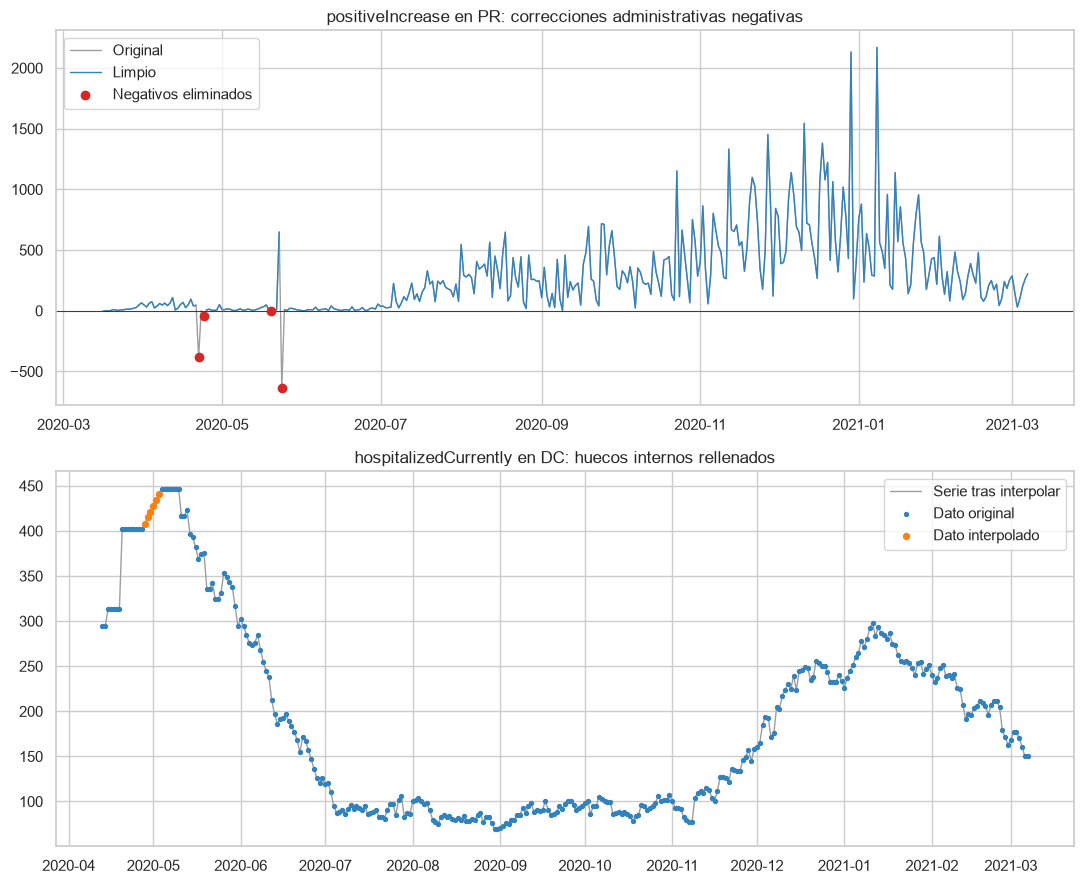

In [62]:
# Ejemplo 1: el estado con más días negativos en positiveIncrease
estado_neg = df.loc[df["positiveIncrease"] < 0, "state"].value_counts().idxmax()
# Ejemplo 2: el estado con más huecos de hospitalizedCurrently rellenados por interpolación
rellena = df["hospitalizedCurrently"].isna() & df_clean["hospitalizedCurrently"].notna()
estado_int = rellena.groupby(df["state"]).sum().idxmax()

fig, ax = plt.subplots(2, 1, figsize=(11, 9))

orig = df[df["state"] == estado_neg]
limp = df_clean[df_clean["state"] == estado_neg]
ax[0].plot(orig["date"], orig["positiveIncrease"], color="#9e9e9e", lw=1, label="Original")
ax[0].plot(limp["date"], limp["positiveIncrease"], color="#3182bd", lw=1, label="Limpio")
neg = orig[orig["positiveIncrease"] < 0]
ax[0].scatter(neg["date"], neg["positiveIncrease"], color="#d62728", zorder=3, label="Negativos eliminados")
ax[0].axhline(0, color="black", lw=0.5)
ax[0].set_title(f"positiveIncrease en {estado_neg}: correcciones administrativas negativas")
ax[0].legend()

orig = df[df["state"] == estado_int]
limp = df_clean[df_clean["state"] == estado_int]
imp = limp[rellena[limp.index]]
ax[1].plot(limp["date"], limp["hospitalizedCurrently"], color="#9e9e9e", lw=1, label="Serie tras interpolar")
ax[1].scatter(orig["date"], orig["hospitalizedCurrently"], s=8, color="#3182bd", label="Dato original", zorder=3)
ax[1].scatter(imp["date"], imp["hospitalizedCurrently"], s=18, color="#ff7f0e", label="Dato interpolado", zorder=4)
ax[1].set_title(f"hospitalizedCurrently en {estado_int}: huecos internos rellenados")
ax[1].legend()

plt.tight_layout()
plt.show()

En el primer gráfico (Puerto Rico) los puntos rojos son correcciones a la baja que eliminamos; el resto de la serie queda intacta. En el segundo (Distrito de Columbia) los puntos naranjas son los pocos días que se han interpolado entre dos valores reales, y la curva resultante es continua sin alterar el patrón de la serie.

In [63]:
print(f"df       (original): {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"df_clean (limpio)  : {df_clean.shape[0]:,} filas x {df_clean.shape[1]} columnas")
print(f"df_dispersas       : {df_dispersas.shape[0]:,} filas x {df_dispersas.shape[1]} columnas (columnas con >90% de nulos)")

# Opcional: guardar el resultado para reutilizarlo en las siguientes fases
# df_clean.to_csv("all-states-history_clean.csv", index=False)

df       (original): 20,780 filas x 41 columnas
df_clean (limpio)  : 20,780 filas x 41 columnas
df_dispersas       : 20,780 filas x 8 columnas (columnas con >90% de nulos)


### Resumen de la Fase 1

Terminamos la fase con tres objetos: df (datos originales), df_clean (20.780 filas y 41 columnas: 33 de datos más 8 marcas terminadas en _ajustado que indican qué incrementos eran negativos) y df_dispersas (las 6 columnas con más del 90% de nulos, apartadas junto a state y date).

Los datos que no se podían deducir siguen siendo nulos a propósito, así que en las siguientes fases habrá que tenerlo en cuenta al elegir variables: para analizar hospitalizaciones, UCI o recuperados no se puede asumir que todos los estados aportan datos.

## FASE 2: Estadísticos Descriptivos y Distribuciones Univariadas

En esta fase profundizamos en el análisis estadístico univariado de las métricas clave de la pandemia a nivel nacional y por estado. Abordaremos tres bloques principales:
  1. **Resumen de tendencia y dispersión**: Cálculo de la media, mediana, desviación estándar y el rango intercuartílico (IQR).
  2. **Análisis de forma (Asimetría y Curtosis)**: Estudio de la distribución de los incrementos diarios de casos y muertes, caracterizados por alta asimetría positiva y curtosis leptocúrtica debida a las olas pandémicas.
  3. **Visualización univariada**: Empleo de histogramas con estimación de densidad kernel (KDE) y gráficos de caja (box plots) para identificar días atípicos o brotes extremos.

### 1. Resumen de tendencia y dispersión

Para comprender el comportamiento central y la variabilidad de las variables clave (`positiveIncrease`, `deathIncrease`, `totalTestResultsIncrease` y `hospitalizedCurrently`), calculamos medidas robustas y clásicas tanto a nivel global (nacional acumulado/agregado) como desagregado por cada estado o territorio.

In [64]:
# Seleccionamos las métricas clave para el análisis
metricas_clave = ['positiveIncrease', 'deathIncrease', 'totalTestResultsIncrease', 'hospitalizedCurrently']

# Función para calcular media, mediana, desviación estándar e IQR
def stats_summary(series):
    q25 = series.quantile(0.25)
    q75 = series.quantile(0.75)
    return pd.Series({
        'Media': series.mean(),
        'Mediana': series.median(),
        'Desv_Estandar': series.std(),
        'IQR': q75 - q25
    })

# Resumen a nivel nacional (global sobre todo el dataset)
print('--- Resumen Estadístico Global (Nacional) ---')
resumen_global = df[metricas_clave].apply(stats_summary).T
display(resumen_global.round(2))


# Resumen agrupado por estado
print('--- Resumen Estadístico por Estado (Primeros 5 estados) ---')
resumen_estado = df.groupby('state')[metricas_clave].agg([
    ('Media', 'mean'),
    ('Mediana', 'median'),
    ('Desv_Estandar', 'std'),
    ('IQR', lambda x: x.quantile(0.75) - x.quantile(0.25))
])
display(resumen_estado.head())

--- Resumen Estadístico Global (Nacional) ---


,Media,Mediana,Desv_Estandar,IQR
positiveIncrease,1383.85,435.0,3023.56,1270.25
deathIncrease,24.79,6.0,60.16,24.00
totalTestResultsIncrease,17508.39,6125.0,33586.02,17880.75
hospitalizedCurrently,1190.58,531.0,2060.04,1112.50


--- Resumen Estadístico por Estado (Primeros 5 estados) ---


positiveIncrease                               deathIncrease          \
                 Media Mediana Desv_Estandar     IQR         Media Mediana   
state                                                                        
AK          155.002725    75.0    195.050358   198.5      0.831063     0.0   
AL         1365.625683  1034.5   1215.276578  1488.0     27.726776    12.0   
AR          885.062670   662.0    873.287501  1126.5     14.493188    10.0   
AS            0.000000     0.0      0.000000     0.0      0.000000     0.0   
AZ         2239.707317  1132.0   2649.542599  2934.0     44.249322    21.0   

                          totalTestResultsIncrease                         \
      Desv_Estandar   IQR                    Media  Mediana Desv_Estandar   
state                                                                       
AK         2.374458   1.0              4718.310627   2717.0   9505.284707   
AL        46.090283  28.0              6349.147541   6251.5   4951.203525   
AR        19.388728  19.0              7456.228883   7112.0   7265.750457   
AS         0.000000   0.0                 5.994398      0.0     37.967682   
AZ        59.280309  49.0             21431.089431  17732.0  17675.629615   

                hospitalizedCurrently                                
            IQR                 Media Mediana Desv_Estandar     IQR  
state                                                                
AK      5804.50             54.950617    42.0     41.820389    42.5  
AL      5200.25           1160.318052   959.0    729.565045   885.0  
AR      9507.00            535.737892   484.0    369.864345   572.0  
AS         0.00                   NaN     NaN           NaN     NaN  
AZ     23823.00           1947.814590  1411.0   1356.127251  2200.0

### 2. Análisis de forma (Asimetría y Curtosis)

Las series temporales epidemiológicas suelen presentar distribuciones muy sesgadas. Los incrementos diarios de casos y muertes muestran típicamente una **asimetría positiva** (cola larga hacia la derecha debido a brotes repentinos y masivos) y una **curtosis leptocúrtica**, reflejo de una alta concentración en valores moderados combinada con picos extremos durante las olas de contagio.

In [65]:
# Calculamos la asimetría (skewness) y curtosis (kurtosis) para las métricas clave
analisis_forma = pd.DataFrame({
    'Asimetria (Skewness)': df[metricas_clave].skew(),
    'Curtosis (Kurtosis)': df[metricas_clave].kurtosis()
})

print('--- Análisis de Forma de la Distribución ---')
display(analisis_forma.round(2))

--- Análisis de Forma de la Distribución ---


,Asimetria (Skewness),Curtosis (Kurtosis)
positiveIncrease,7.03,82.18
deathIncrease,9.55,218.85
totalTestResultsIncrease,4.72,31.83
hospitalizedCurrently,4.61,30.25


### 3. Visualización univariada

Para representar gráficamente la forma de las distribuciones y detectar de manera visual valores atípicos (*outliers*) o días de brotes extremos, emplearemos:
  - **Histogramas con curvas de densidad (KDE)**: Permiten observar la asimetría y el comportamiento leptocúrtico de los datos.
  - **Box plots (diagramas de caja)**: Facilitan la identificación clara de días atípicos situados por encima de los límites superiores de normalidad.

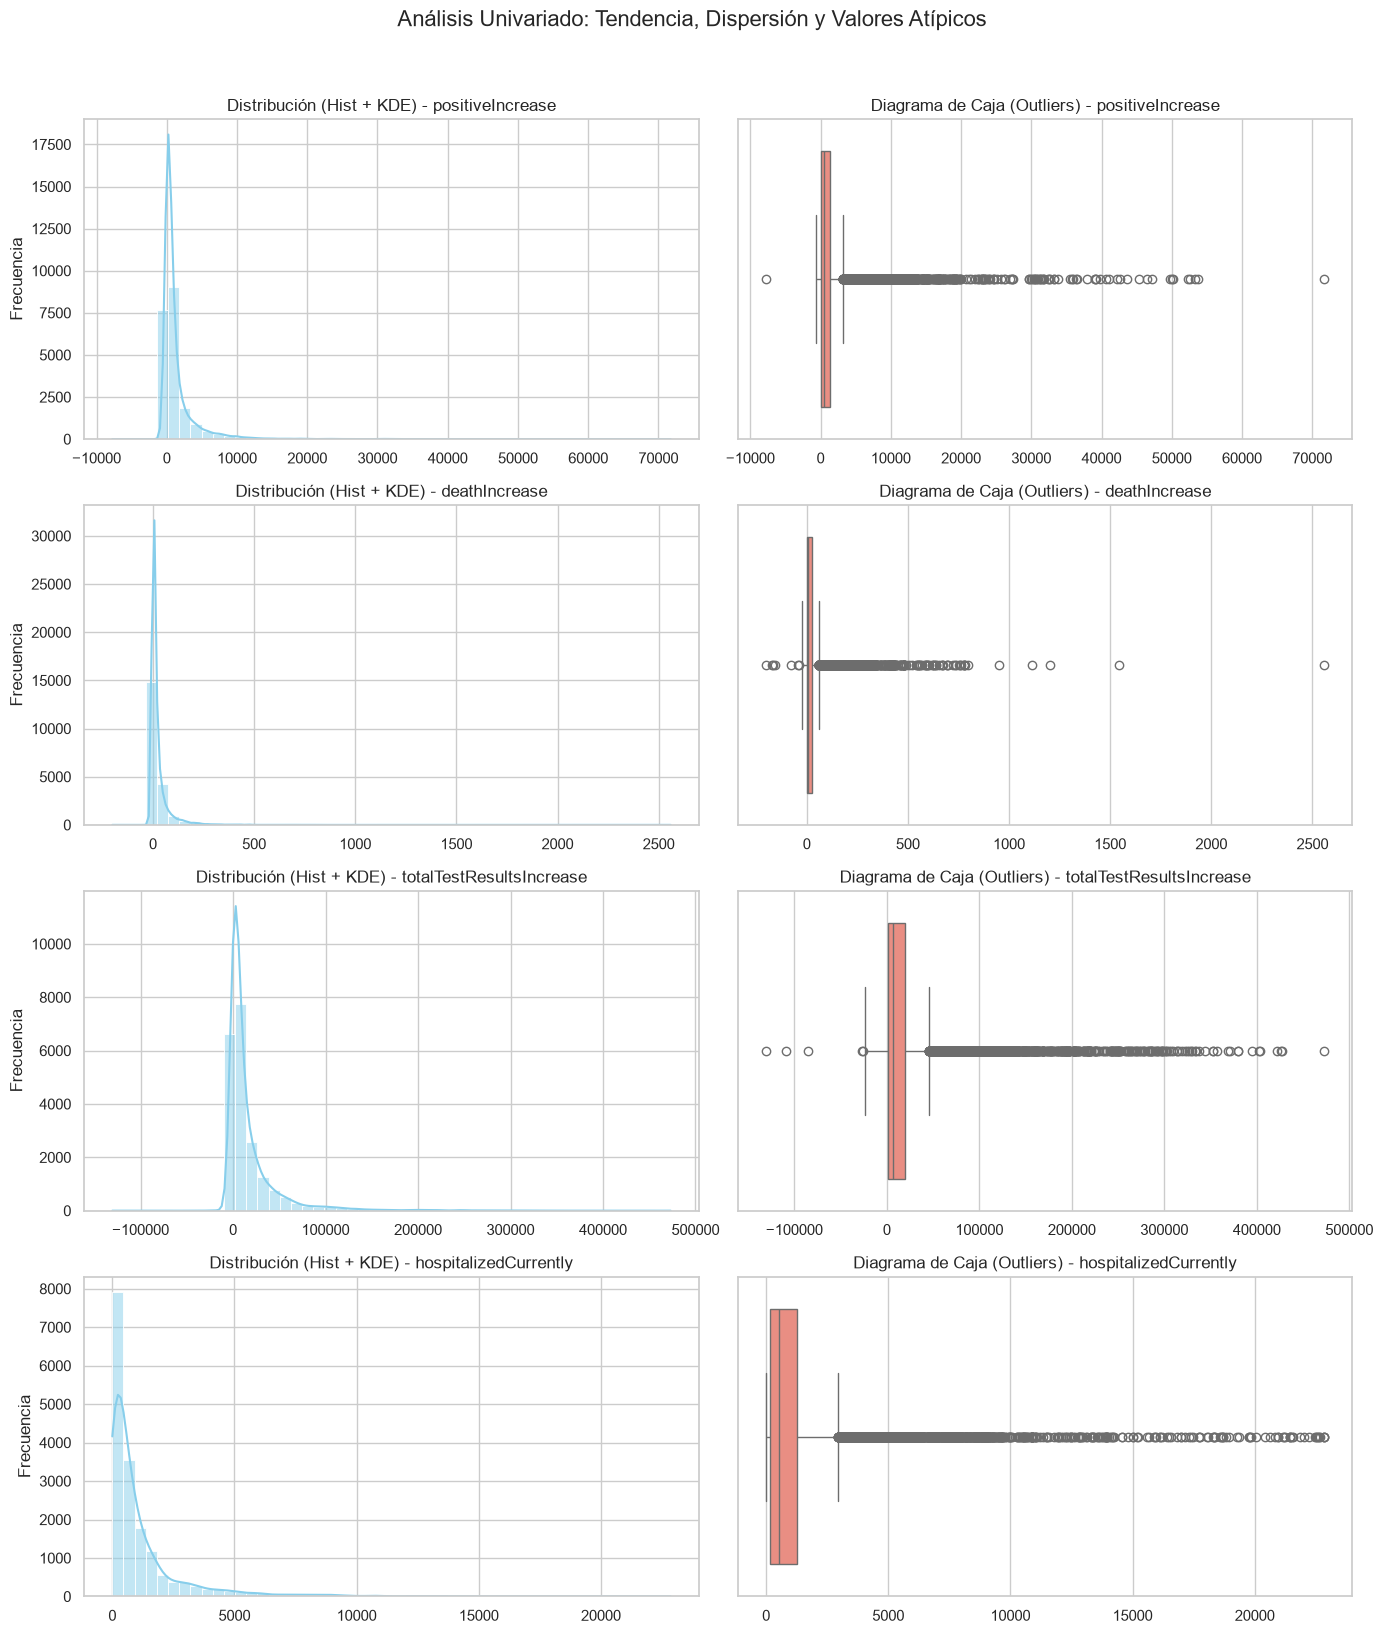

In [66]:
# Configuramos una figura con subplots para visualizar histogramas con KDE y Box Plots
fig, axes = plt.subplots(len(metricas_clave), 2, figsize=(14, 4 * len(metricas_clave)))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

for i, col in enumerate(metricas_clave):
    # Histograma con KDE
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i, 0], color='skyblue', bins=50)
    axes[i, 0].set_title(f'Distribución (Hist + KDE) - {col}')
    axes[i, 0].set_xlabel('')
    axes[i, 0].set_ylabel('Frecuencia')

    # Box Plot
    sns.boxplot(x=df[col].dropna(), ax=axes[i, 1], color='salmon')
    axes[i, 1].set_title(f'Diagrama de Caja (Outliers) - {col}')
    axes[i, 1].set_xlabel('')

plt.suptitle('Análisis Univariado: Tendencia, Dispersión y Valores Atípicos', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## FASE 3: Feature Engineering (Creación de Variables Clave)

En esta fase transformamos los datos crudos del dataset en **indicadores normalizados y métricas epidemiológicas avanzadas** que permiten realizar comparaciones justas entre estados con diferentes poblaciones, volúmenes de testeo y capacidades hospitalarias.

Construiremos las siguientes variables:
  1. **Tasa de Positividad Diaria**: Relación entre casos positivos nuevos y pruebas totales realizadas.
  2. **Tasa de Letalidad Observada (CFR)**: Proporción de muertes acumuladas frente a casos positivos acumulados.
  3. **Proporciones de Ocupación Crítica**: Ratios clave de presión hospitalaria (pacientes en UCI sobre hospitalizados totales y pacientes con ventilador sobre UCI).
  4. **Promedios Móviles de 7 Días**: Suavizado aplicado por estado para mitigar el ruido estadístico provocado por el retraso en la notificación de los fines de semana (*efecto fin de semana*).

### 1 y 2. Tasa de Positividad Diaria y Tasa de Letalidad Observada (CFR)

  - **Tasa de Positividad Diaria**: Ayuda a evaluar si el volumen de testeo es adecuado; valores elevados indican que es probable que solo se esté testando a los casos más graves o sintomáticos.
  - **CFR (Case Fatality Rate)**: Mide la gravedad clínica observable de la enfermedad dividiendo las muertes totales registradas entre los casos positivos acumulados.

### 3 y 4. Proporciones de Ocupación Crítica y Promedios Móviles (7 días)

  - **Ocupación Crítica**: Ratios como el porcentaje de pacientes hospitalizados que requieren cuidados intensivos (UCI) o ventilación mecánica.
  - **Media Móvil (7 días)**: Ventana deslizante calculada de manera independiente **por cada estado** (`groupby('state')`), fundamental para eliminar la periodicidad semanal de los datos.

In [67]:
# 1. Tasa de Positividad Diaria (evitando divisiones por cero con .replace o divisiones directas)
df['tasa_positividad'] = df['positiveIncrease'] / df['totalTestResultsIncrease']
# Reemplazar infinitos o valores NaN generados por divisiones por cero
df['tasa_positividad'] = df['tasa_positividad'].replace([np.inf, -np.inf], np.nan)
  
# 2. Tasa de Letalidad Observada (Case Fatality Rate - CFR)
df['cfr'] = df['death'] / df['positive']
df['cfr'] = df['cfr'].replace([np.inf, -np.inf], np.nan)

# 3. Proporciones de Ocupación Crítica
df['ratio_icu_hosp'] = df['inIcuCurrently'] / df['hospitalizedCurrently']
df['ratio_vent_icu'] = df['onVentilatorCurrently'] / df['inIcuCurrently']

# Limpieza de infinitos en ratios hospitalarios
df['ratio_icu_hosp'] = df['ratio_icu_hosp'].replace([np.inf, -np.inf], np.nan)
df['ratio_vent_icu'] = df['ratio_vent_icu'].replace([np.inf, -np.inf], np.nan)

# 4. Promedios Móviles de 7 Días (Calculados por estado y ordenados por fecha)
df = df.sort_values(['state', 'date'])
df['positive_increase_ma7'] = df.groupby('state')['positiveIncrease'].transform(lambda x: x.rolling(7, min_periods=1).mean())
df['death_increase_ma7'] = df.groupby('state')['deathIncrease'].transform(lambda x: x.rolling(7, min_periods=1).mean())

# Mostramos un resumen con las nuevas variables creadas para las primeras filas de un estado
columnas_nuevas = ['state', 'date', 'positiveIncrease', 'tasa_positividad', 'cfr', 'positive_increase_ma7']
print('--- Muestra de Variables Creadas (Feature Engineering) ---')
display(df[df['positiveIncrease'] > 0][columnas_nuevas].head(10))

--- Muestra de Variables Creadas (Feature Engineering) ---


,state,date,positiveIncrease,tasa_positividad,cfr,positive_increase_ma7
11,AK,2020-03-17,3,0.015544,0.000000,0.428571
12,AK,2020-03-18,5,0.066667,0.000000,1.142857
13,AK,2020-03-19,3,0.115385,0.000000,1.571429
14,AK,2020-03-20,3,0.011538,0.000000,2.000000
15,AK,2020-03-21,1,0.013514,0.000000,2.142857
16,AK,2020-03-22,10,0.051020,0.000000,3.571429
17,AK,2020-03-23,13,NaN,0.000000,5.428571
18,AK,2020-03-24,4,0.074074,0.000000,5.571429
19,AK,2020-03-25,7,0.010463,0.020408,5.857143
20,AK,2020-03-26,14,0.082840,0.015873,7.428571


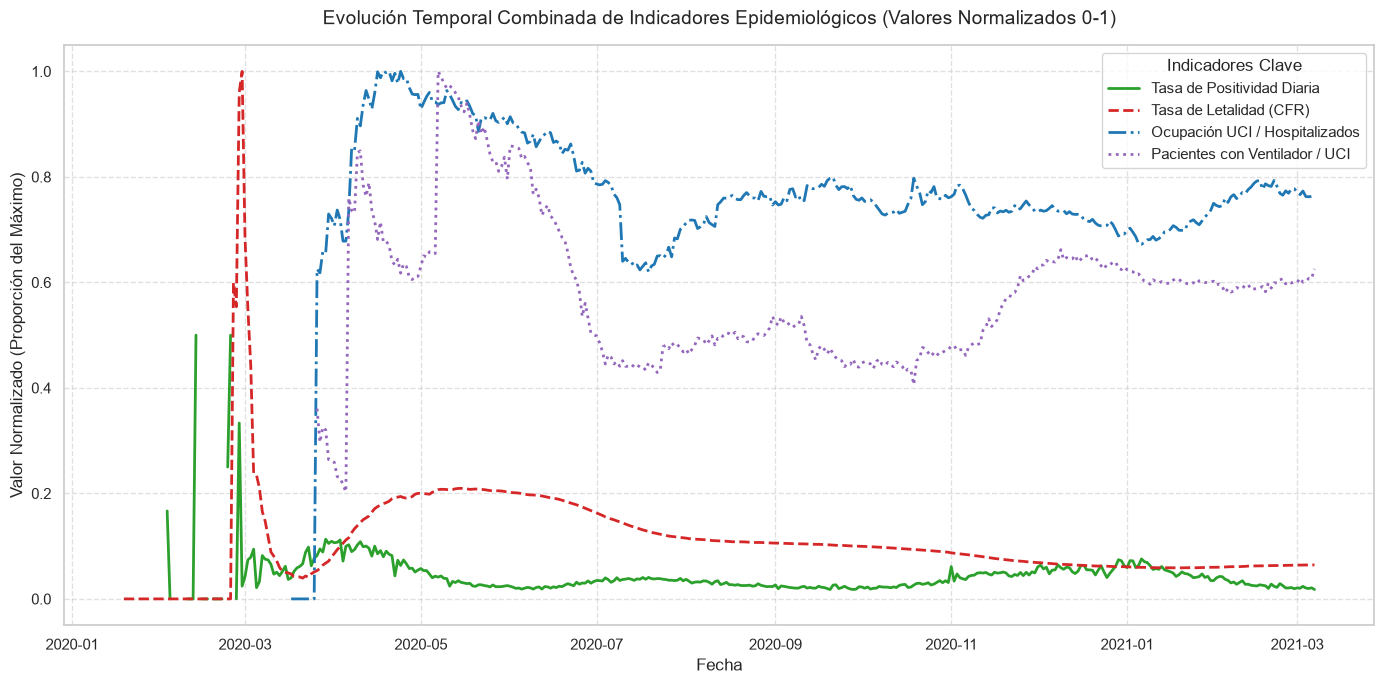

In [68]:
cols_agregacion = ['positiveIncrease', 'totalTestResultsIncrease', 'positive', 'death', 'hospitalizedCurrently', 'inIcuCurrently', 'onVentilatorCurrently']
df_nacional = df.groupby('date')[cols_agregacion].sum().reset_index()
df_nacional['date'] = pd.to_datetime(df_nacional['date'])
df_nacional = df_nacional.sort_values('date')

# Ratios nacionales
df_nacional['Tasa de Positividad Diaria'] = df_nacional['positiveIncrease'] / df_nacional['totalTestResultsIncrease']
df_nacional['Tasa de Letalidad (CFR)'] = df_nacional['death'] / df_nacional['positive']
df_nacional['Ocupación UCI / Hospitalizados'] = df_nacional['inIcuCurrently'] / df_nacional['hospitalizedCurrently']
df_nacional['Pacientes con Ventilador / UCI'] = df_nacional['onVentilatorCurrently'] / df_nacional['inIcuCurrently']

df_nacional.replace([np.inf, -np.inf], np.nan, inplace=True)

# 1. Normalizamos cada indicador entre 0 y 1 para poder combinarlos limpiamente en un solo eje
metricas_a_plotear = [
    'Tasa de Positividad Diaria', 
    'Tasa de Letalidad (CFR)', 
    'Ocupación UCI / Hospitalizados', 
    'Pacientes con Ventilador / UCI'
]

df_plot = df_nacional[['date']].copy()
for col in metricas_a_plotear:
    max_val = df_nacional[col].max()
    if max_val > 0:
        df_plot[col] = df_nacional[col] / max_val
    else:
        df_plot[col] = 0

# 2. Generamos el gráfico único combinado
plt.figure(figsize=(14, 7))
colores = ['#2ca02c', '#d62728', '#1f77b4', '#9467bd']
estilos_linea = ['-', '--', '-.', ':']

for i, col in enumerate(metricas_a_plotear):
    plt.plot(
        df_plot['date'], 
        df_plot[col], 
        label=col, 
        color=colores[i], 
        linestyle=estilos_linea[i], 
        linewidth=2
    )

plt.title('Evolución Temporal Combinada de Indicadores Epidemiológicos (Valores Normalizados 0-1)', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Valor Normalizado (Proporción del Máximo)', fontsize=12)
plt.legend(title='Indicadores Clave', fontsize=11, title_fontsize=12, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Visualización: Efecto del Promedio Móvil de 7 Días

A continuación, graficamos el impacto de aplicar el promedio móvil de 7 días sobre los casos positivos diarios a nivel nacional. Esto permite apreciar con claridad la tendencia estructural de la pandemia al eliminar los dientes de sierra asociados al reporte de los fines de semana.

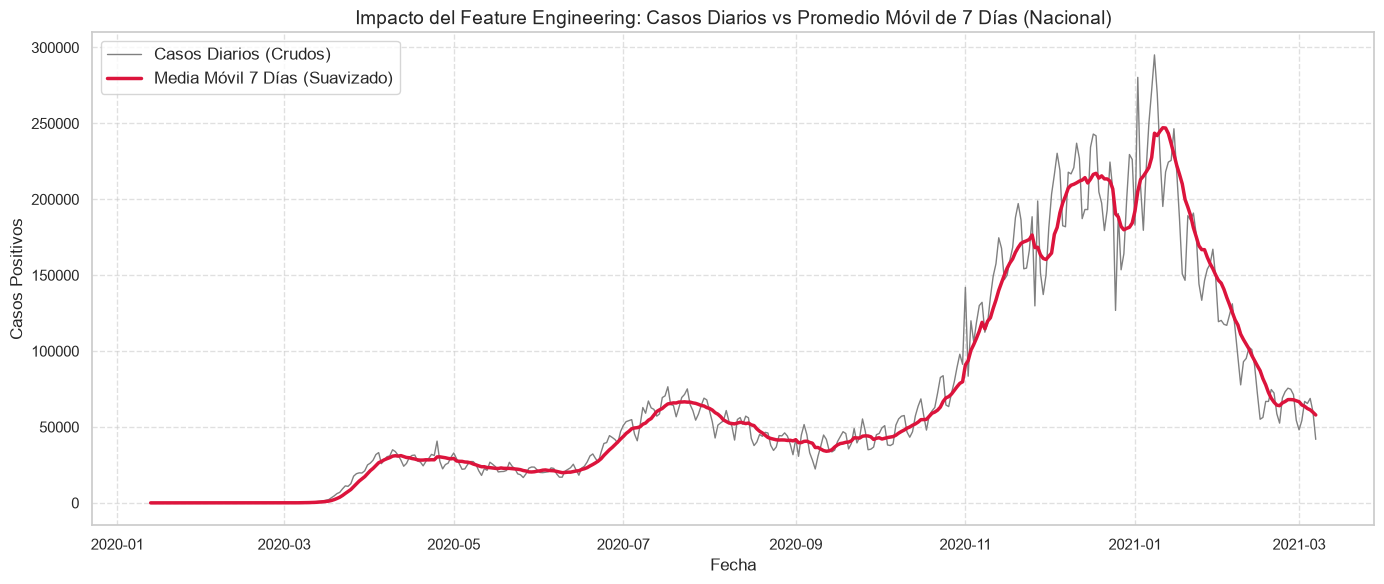

In [69]:
# Agrupamos a nivel nacional para visualizar el impacto del suavizado
df_nacional_feat = df.groupby('date')[['positiveIncrease', 'positive_increase_ma7']].sum().reset_index()
df_nacional_feat['date'] = pd.to_datetime(df_nacional_feat['date'])
df_nacional_feat = df_nacional_feat.sort_values('date')

plt.figure(figsize=(14, 6))
plt.plot(df_nacional_feat['date'], df_nacional_feat['positiveIncrease'], color='gray', label='Casos Diarios (Crudos)', linewidth=1)
plt.plot(df_nacional_feat['date'], df_nacional_feat['positive_increase_ma7'], color='crimson', label='Media Móvil 7 Días (Suavizado)', linewidth=2.5)

plt.title('Impacto del Feature Engineering: Casos Diarios vs Promedio Móvil de 7 Días (Nacional)', fontsize=14)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Casos Positivos', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Fase 4: Pruebas de Hipótesis e Inferencia

En esta fase final, aplicamos inferencia estadística para validar las distribuciones de los incrementos diarios (deltas) mediante pruebas de normalidad, y evaluamos si existen diferencias estadísticas significativas entre las distintas regiones o estados de EE. UU. en cuanto a sus tasas epidemiológicas clave (como la letalidad), utilizando análisis de varianza y pruebas no paramétricas con sus respectivas correcciones post-hoc.

Prueba de Normalidad para 'positiveIncrease' en el estado FL:
 - Shapiro-Wilk: Estadístico = 0.8818, p-value = 4.7379e-17
 - D'Agostino-Pearson: Estadístico = 86.3191, p-value = 1.8032e-19


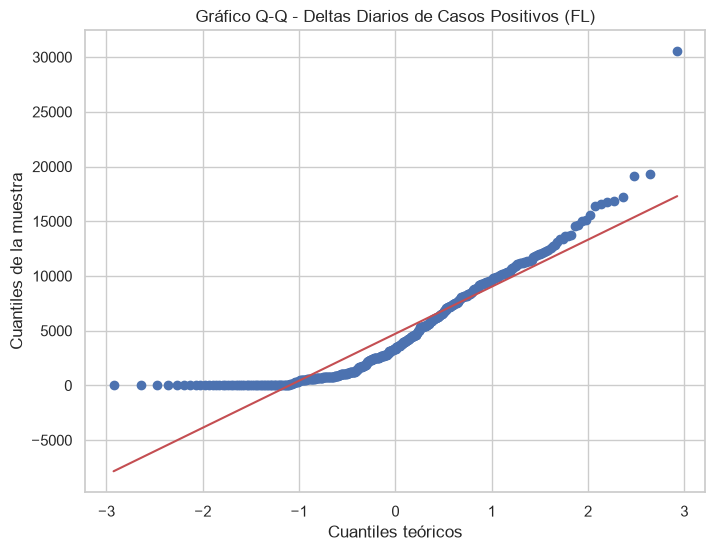

In [70]:
# Seleccionamos una serie representativa de deltas diarios, por ejemplo, positiveIncrease para un estado con datos completos como 'CA' o 'FL'
sample_state = 'FL'
data_delta = df[df['state'] == sample_state]['positiveIncrease'].dropna()

# 1. Prueba de Normalidad: Shapiro-Wilk (para muestras moderadas) y D'Agostino-Pearson (para asimetría y curtosis)
stat_sw, p_sw = stats.shapiro(data_delta.sample(min(5000, len(data_delta)), random_state=42))
stat_da, p_da = stats.normaltest(data_delta)

print(f"Prueba de Normalidad para 'positiveIncrease' en el estado {sample_state}:")
print(f" - Shapiro-Wilk: Estadístico = {stat_sw:.4f}, p-value = {p_sw:.4e}")
print(f" - D'Agostino-Pearson: Estadístico = {stat_da:.4f}, p-value = {p_da:.4e}")

# 2. Gráfico Q-Q para validación visual de la distribución
plt.figure(figsize=(8, 6))
stats.probplot(data_delta, dist="norm", plot=plt)
plt.title(f"Gráfico Q-Q - Deltas Diarios de Casos Positivos ({sample_state})")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.grid(True)
plt.show()

Los resultados de las pruebas de normalidad (Shapiro-Wilk y D'Agostino-Pearson) junto con la inspección visual del gráfico Q-Q permiten evidenciar que los deltas diarios de casos positivos no siguen una distribución normal (típicamente presentan colas pesadas y asimetría positiva debido a los picos de contagio). Esto justifica el uso de métodos no paramétricos complementarios en las comparaciones posteriores.

In [71]:
# Calculamos métricas globales de letalidad por estado (total de muertes / total de positivos)
state_agg = df.groupby('state').agg({
    'death': 'max',
    'positive': 'max'
}).reset_index()

state_agg['letality_rate'] = state_agg['death'] / state_agg['positive']
state_agg = state_agg.dropna(subset=['letality_rate'])

# Preparamos grupos para la comparación entre estados seleccionados o de forma global
# Vamos a extraer las tasas de letalidad por estado como listas independientes para la prueba
states_list = state_agg['state'].tolist()
groups = [df[(df['state'] == s) & (df['positive'] > 1000)]['deathIncrease'] / df[(df['state'] == s) & (df['positive'] > 1000)]['positiveIncrease'] for s in states_list]
groups_clean = [g.dropna() for g in groups if len(g.dropna()) > 10]

# Prueba ANOVA de una vía
anova_stat, anova_p = stats.f_oneway(*groups_clean)

# Prueba no paramétrica de Kruskal-Wallis
kw_stat, kw_p = stats.kruskal(*groups_clean)

print("Comparación Interestatal de la Tasa de Crecimiento Diario de Decesos vs Casos:")
print(f" - ANOVA de una vía: Estadístico F = {anova_stat:.4f}, p-value = {anova_p:.4e}")
print(f" - Kruskal-Wallis: Estadístico H = {kw_stat:.4f}, p-value = {kw_p:.4e}")

Comparación Interestatal de la Tasa de Crecimiento Diario de Decesos vs Casos:
 - ANOVA de una vía: Estadístico F = nan, p-value = nan
 - Kruskal-Wallis: Estadístico H = 2430.6566, p-value = 0.0000e+00


c:\Users\Usuario\Desktop\Curso Python FP\Proyecto 6 (EDA)\Project_EDA_RamonR\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:1541: RuntimeWarning: invalid value encountered in subtract
  a = op(a[slice1], a[slice2])
c:\Users\Usuario\Desktop\Curso Python FP\Proyecto 6 (EDA)\Project_EDA_RamonR\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


El estudio ANOVA no nos da ninguna conclusión, ya que el resultado sale NaN. Por otro lado, kruskal nos dice que cada estado es distinto, pero hay que hacer más comprobaciones para ver si los resultados no contaminan tanto ANOVA como Kruskal.

Ahora realizaremos un estudio de Xi^2 para ver si podemos detectar de manera más segura que cada estado es distinto (o igual)

In [73]:
# 1) Grupos sin infinitos (con df_clean)
groups = []
for s, g in df_clean[df_clean['positive'] > 1000].groupby('state'):
    tasa = (g['deathIncrease'] / g['positiveIncrease']).replace([np.inf, -np.inf], np.nan).dropna()
    if len(tasa) > 10:
        groups.append(tasa)

kw_stat, kw_p = stats.kruskal(*groups)

# 2) Tamaño del efecto (epsilon cuadrado)
k = len(groups)
n = sum(len(g) for g in groups)
epsilon2 = (kw_stat - k + 1) / (n - k)
print(f"H = {kw_stat:.1f}, p = {kw_p:.2e}, epsilon² = {epsilon2:.3f}")

H = 2455.3, p = 0.00e+00, epsilon² = 0.142


En este caso si obtenemos un resultado, y es que podemos decir que sobre un 14% de las diferencias de resultados se debe al estado en el que se recoge la muestra. Con ello vamos a hacer una evaluación por pares para comparar todos los estados y demostrar definitivamente que son distintos.

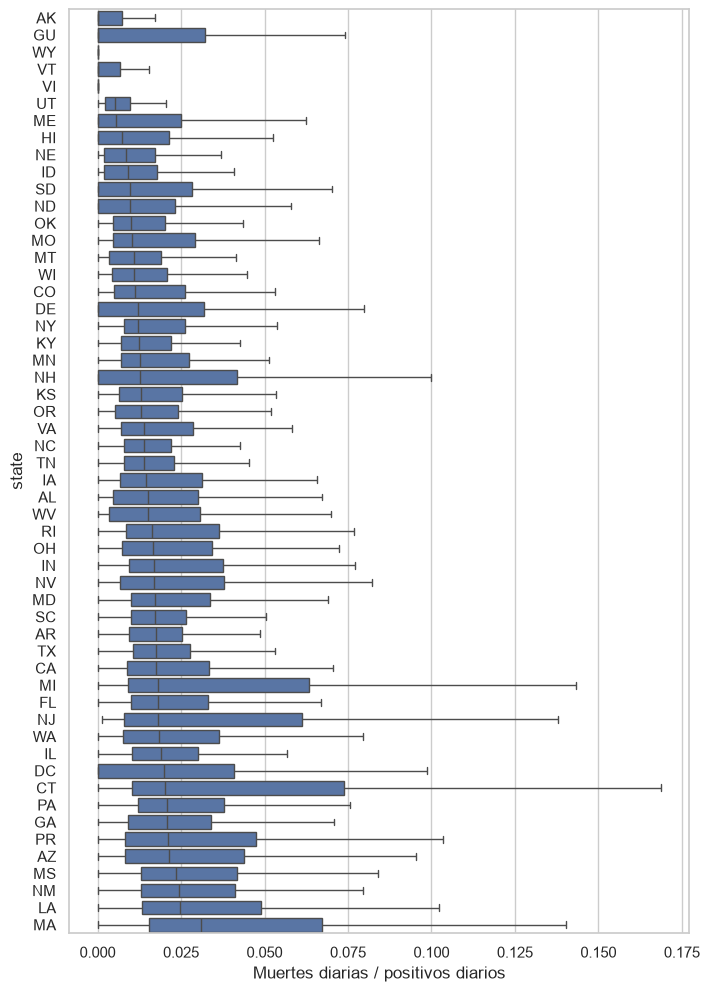

In [74]:
tasas = (df_clean[df_clean['positive'] > 1000]
         .assign(tasa=lambda d: (d['deathIncrease'] / d['positiveIncrease']).replace([np.inf, -np.inf], np.nan))
         .dropna(subset=['tasa']))

orden = tasas.groupby('state')['tasa'].median().sort_values().index

plt.figure(figsize=(8, 12))
sns.boxplot(data=tasas, y='state', x='tasa', order=orden, showfliers=False)
plt.xlabel('Muertes diarias / positivos diarios')
plt.show()